In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.datasets import load_breast_cancer
X,y = load_breast_cancer(return_X_y=True, as_frame=True)

In [ ]:
X_train, X_hold, y_train, y_hold = train_test_split(X, y, test_size=0.4, random_state=1, stratify=y)
X_valid, X_test, y_valid, y_test = train_test_split(X_hold, y_hold, test_size=0.5, random_state=1, stratify=y_hold)

print(y_train.shape)
print(y_valid.shape)
print(y_test.shape)

(341,)
(114,)
(114,)


c:\Users\munas\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Training Accuracy (Logistic Regression):   0.9912
Validation Accuracy (Logistic Regression): 0.9912


c:\Users\munas\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 5000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=5000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


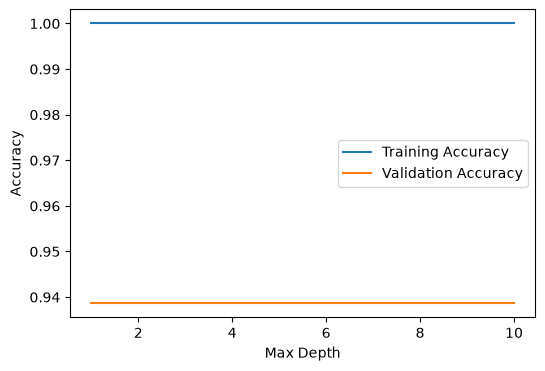

Training Accuracy (Random Forest):   1.0
Validation Accuracy (Random Forest): 0.9298


In [20]:
# Task 1

# Logistic Classifier

logreg_mod = model_2 = LogisticRegression(solver='lbfgs', penalty=None, max_iter=5000)
logreg_mod.fit(X_train, y_train)

print('Training Accuracy (Logistic Regression):  ', round(logreg_mod.score(X_train, y_train),4))
print('Validation Accuracy (Logistic Regression):', round(logreg_mod.score(X_test, y_test),4))

# Decision Tree Classifier

tr_acc = []
va_acc = []

depth_list = range(1,11)

for d in depth_list:
    temp_mod = DecisionTreeClassifier(max_depth=32, random_state=1)
    temp_mod.fit(X_train, y_train)
    tr_acc.append(temp_mod.score(X_train, y_train))
    va_acc.append(temp_mod.score(X_valid, y_valid))
    
plt.figure(figsize=([6,4]))
plt.plot(depth_list, tr_acc, label='Training Accuracy')
plt.plot(depth_list, va_acc, label='Validation Accuracy')
plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Random Forest Classifier

forest_mod = RandomForestClassifier(n_estimators=500, max_depth=32, random_state=1)
forest_mod.fit(X_train, y_train)

print('Training Accuracy (Random Forest):  ', round(forest_mod.score(X_train, y_train),4))
print('Validation Accuracy (Random Forest):', round(forest_mod.score(X_valid, y_valid),4))

#

In [25]:
# Task 2
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

# confusion matrix for Decision Tree
cm_decision = confusion_matrix(y_valid, temp_mod.predict(X_valid))
print('Confusion Matrix (Decision Tree):\n', cm_decision)
pd.DataFrame(cm_decision, index=['Actual 0', 'Actual 1'], columns=['Predicted 0', 'Predicted 1'])

# confusion matrix for Random Forest
cm_forest = confusion_matrix(y_valid, forest_mod.predict(X_valid))
print('Confusion Matrix (Random Forest):\n', cm_forest)
pd.DataFrame(cm_forest, index=['Actual 0', 'Actual 1'], columns=['Predicted 0', 'Predicted 1'])

# confusion matrix for Logistic Regression
cm_logreg = confusion_matrix(y_test, logreg_mod.predict(X_test))
print('Confusion Matrix (Logistic Regression):\n', cm_logreg)
pd.DataFrame(cm_logreg, index=['Actual 0', 'Actual 1'], columns=['Predicted 0', 'Predicted 1'])

Confusion Matrix (Decision Tree):
 [[38  5]
 [ 2 69]]
Confusion Matrix (Random Forest):
 [[39  4]
 [ 4 67]]
Confusion Matrix (Logistic Regression):
 [[42  0]
 [ 1 71]]


,Predicted 0,Predicted 1
Actual 0,42,0
Actual 1,1,71


In [ ]:
# Task 2 (Precison and Recall)

# Classification report for Decision Tree
print('Classification Report (Decision Tree):\n', classification_report(y_valid, temp_mod.predict(X_valid)))

# Classification report for Random Forest
print('Classification Report (Random Forest):\n', classification_report(y_valid, forest_mod.predict(X_valid)))

# Classification report for Logistic Regression
print('Classification Report (Logistic Regression):\n', classification_report(y_test, logreg_mod.predict(X_test)))


Classification Report (Decision Tree):
               precision    recall  f1-score   support

           0       0.95      0.88      0.92        43
           1       0.93      0.97      0.95        71

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114

Classification Report (Random Forest):
               precision    recall  f1-score   support

           0       0.91      0.91      0.91        43
           1       0.94      0.94      0.94        71

    accuracy                           0.93       114
   macro avg       0.93      0.93      0.93       114
weighted avg       0.93      0.93      0.93       114

Classification Report (Logistic Regression):
               precision    recall  f1-score   support

           0       0.98      1.00      0.99        42
           1       1.00      0.99      0.99        72

    accuracy                           0.99       114
  

In [ ]:
# Task 3
print("We will use the logistic regression model because it has the best recall and precision scores")

Task 4

a) Our testing for malignant tumors is very precise. Our model has a 98% success rate, meaninf your chance of having a malignant tumor is 98%.


b) Our testing for benign tumor is perfectly accurate, which means everyone who gets diagnosed for benign tumors actually has one.


Task 5

A model like this prioritizes recall and will reduce false negatives, usually at the cost of more false positives. This means that the patient will have more peace of mind when given a negative result, they also are less likely to miss a diagnoses if it's actually there. However, if they are over diagnosed, which this model tends to lead towards, then the patient may be anxious about it and may end up having to pay for unnecessary treatment. For the instition, this is good because more cancers caught and treated means more people survive, since treating cancer early on is much easier than late in the game. On the other hand, more false diagnoses may result in a loss of trust from the patients as well as higher costs due to more screening and treatment procedures.